# Walkthrough: Preparing data for METIS

Before training a surrogate, you need a dataset of simulator inputs
(parameters) paired with outputs (realisations).

> **Tip**
>
> This walkthrough uses Python to prepare the data and expects that you
> have packages like matplotlib, pandas and numpy installed. However,
> you can use any language or packages you’re comfortable with.

## Flattening a single realisation

METIS expects the timeseries realisations to be stored in parquet files
in a flat format. For example, let’s consider a single realisation where
the columm ‘a’ varies over time.

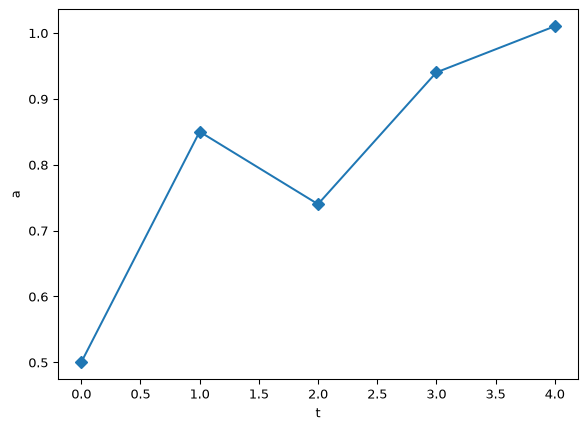

In [1]:
import matplotlib.pyplot as plt

a = [0.5, 0.85, 0.74, 0.94, 1.01]
plt.plot(a, marker='D')
plt.xlabel('t')
plt.ylabel('a')
plt.show()

Then in a ‘flat’ format this data would have 5 rows, and two columns:

In [2]:
import pandas as pd

pd.DataFrame({'a':a, 't':range(5)})

## Multiple SIRDS realisations

For the SIRDS simulator we also need to store the simulator’s inputs and
disambiguate between different realisations with the same inputs.
Simulator inputs are just treated as another column, and different
realisations are disambiguated via the ‘rep’ column:

In [3]:
import numpy as np
import pandas as pd


def simulate_sirds(
    I0=0.005, beta=0.4, gamma=0.1, omega=0.02, mu=0.01, T=365, dt=1.0, N=1000, seed=None
):
    rng = np.random.default_rng(seed)
    n = int(T / dt) + 1
    I0_count = max(0, min(N, int(round(I0 * N))))

    S = np.zeros(n, dtype=np.int32)
    I = np.zeros(n, dtype=np.int32)
    R = np.zeros(n, dtype=np.int32)
    D = np.zeros(n, dtype=np.int32)
    S[0], I[0], R[0], D[0] = N - I0_count, I0_count, 0, 0

    for k in range(n - 1):
        p_inf = 1.0 - np.exp(-beta * I[k] / N * dt)
        p_rec = 1.0 - np.exp(-gamma * dt)
        p_die = 1.0 - np.exp(-mu * dt)
        p_sus = 1.0 - np.exp(-omega * dt)

        new_I = rng.binomial(S[k], p_inf)

        # Competing risks: each infected individual can recover, die, or stay infected.
        # Use a multinomial draw so recovery + death never exceeds I[k].
        p_stay = max(0.0, 1.0 - p_rec - p_die)
        outcomes = rng.multinomial(I[k], [p_rec, p_die, p_stay])
        new_R = outcomes[0]
        new_D = outcomes[1]

        new_S = rng.binomial(R[k], p_sus)

        S[k + 1] = S[k] - new_I + new_S
        I[k + 1] = I[k] + new_I - new_R - new_D
        R[k + 1] = R[k] + new_R - new_S
        D[k + 1] = D[k] + new_D

    return S, I, R, D

In [4]:
# the simulator inputs
params = dict(I0=0.005, beta=0.4, gamma=0.1, omega=0.02, mu=0.01)

# number of realisations we would like 
n_reps = 5
 
frames = []
for rep in range(n_reps):
    
    S, I, R, D = simulate_sirds(seed=rep, **params, T=100)
    S,I,R,D=S[1:],I[1:],R[1:], D[1:] # we drop t=0 since for this simulator it carries no information
    t = np.arange(len(S))
    frames.append(pd.DataFrame({
        "rep": rep,
        "t": t,
        "I_t": I,
        "S_t": S,
        "R_t": R,
        "I_0": params["I0"],
        "beta": params["beta"],
        "gamma": params["gamma"],
        "omega": params["omega"],
        "mu":params["mu"],
    }))
    df = pd.concat(frames, ignore_index=True)

print(f"reps:  {df['rep'].unique()}")
df

reps:  [0 1 2 3 4]

500 rows × 10 columns

## Sampling the parameter space

When building a dataset of simulator realisations its important to
consider which regions of the simulator’s parameter (or input) space you
sample and how they are sampled. For example, a simulator may be more
sensitive in a certain parameter region or parameters physically
constrained to lie within a particular range. For our example we will
simply sample uniformly within reasonable ranges but another popular
approach is Latin Hypercube Sampling (see [Scipy Latin
Hypercube](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.qmc.LatinHypercube.html)).

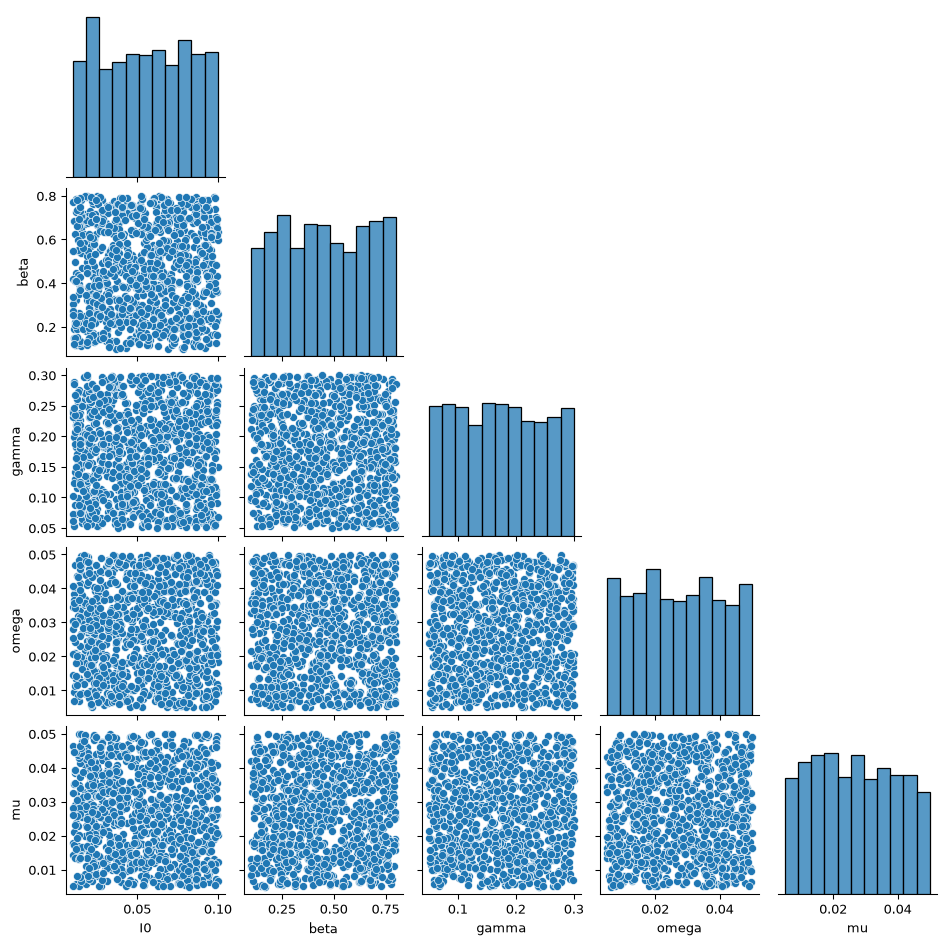

In [5]:
import seaborn as sns

N_PARAMS = 1_000

# reproducible parameter sampling
param_rng = np.random.default_rng(42)
I0_vals = param_rng.uniform(0.01, 0.1, N_PARAMS)
beta_vals = param_rng.uniform(0.10, 0.80, N_PARAMS)
gamma_vals = param_rng.uniform(0.05, 0.30, N_PARAMS)
omega_vals = param_rng.uniform(0.005, 0.05, N_PARAMS)
mu_vals = param_rng.uniform(0.005, 0.05, N_PARAMS)

#visualise the sampled space
sns.pairplot(
    pd.DataFrame({'I0':I0_vals, 'beta':beta_vals, 'gamma':gamma_vals, 'omega':omega_vals, 'mu':mu_vals}), corner=True,height=2
)

## Creating the full dataset

Given our parameters we can now create an entire dataset.

In [6]:
import time
N_REPS = 5
T, DT = 200, 1.0
n_steps_sim = int(T / DT) + 1  # simulator produces this many steps including t=0
n_steps = n_steps_sim - 1  # we drop t=0 since it carries no information
total_rows = N_PARAMS * N_REPS * n_steps


# preallocate
t_template = np.arange(1, n_steps_sim) * DT
rep = np.empty(total_rows, dtype=np.int32)
t_col = np.empty(total_rows, dtype=np.float32)
I_col = np.empty(total_rows, dtype=np.int32)
S_col = np.empty(total_rows, dtype=np.int32)
R_col = np.empty(total_rows, dtype=np.int32)
D_col = np.empty(total_rows, dtype=np.int32)
I0_col = np.empty(total_rows, dtype=np.float32)
beta_col = np.empty(total_rows, dtype=np.float32)
gamma_col = np.empty(total_rows, dtype=np.float32)
omega_col = np.empty(total_rows, dtype=np.float32)
mu_col = np.empty(total_rows, dtype=np.float32)

print(f"Running {N_PARAMS} × {N_REPS} = {N_PARAMS * N_REPS} simulations...")
t0 = time.time()

row = 0
for i in range(N_PARAMS):
    params = dict(
        I0=I0_vals[i], beta=beta_vals[i], gamma=gamma_vals[i], omega=omega_vals[i], mu=mu_vals[i]
    )
    for r in range(N_REPS):
        seed = i * N_REPS + r  # unique across all runs
        S, I, R,D = simulate_sirds(seed=seed, T=T, dt=DT, **params)

        sl = slice(row, row + n_steps)
        rep[sl] = r + 1  # 1..5
        t_col[sl] = t_template
        I_col[sl] = I[1:]
        S_col[sl] = S[1:]
        R_col[sl] = R[1:]
        D_col[sl] = D[1:]
        I0_col[sl] = params["I0"]
        beta_col[sl] = params["beta"]
        gamma_col[sl] = params["gamma"]
        omega_col[sl] = params["omega"]
        mu_col[sl] = params["mu"]
        row += n_steps

    if (i + 1) % 100 == 0:
        print(f"  {i + 1}/{N_PARAMS} inputs done ({time.time() - t0:.1f}s)")

Running 1000 × 5 = 5000 simulations...
  100/1000 inputs done (0.4s)
  200/1000 inputs done (0.7s)
  300/1000 inputs done (1.1s)
  400/1000 inputs done (1.4s)
  500/1000 inputs done (1.7s)
  600/1000 inputs done (2.1s)
  700/1000 inputs done (2.4s)
  800/1000 inputs done (2.8s)
  900/1000 inputs done (3.1s)
  1000/1000 inputs done (3.4s)

In [7]:
df = pd.DataFrame(
    {
        "rep": rep,
        "t": t_col,
        "I_t": I_col,
        "S_t": S_col,
        "R_t": R_col,
        "D_t": D_col,
        "I_0": I0_col,
        "beta": beta_col,
        "gamma": gamma_col,
        "omega": omega_col,
        "mu": mu_col,
    }
)

df

1000000 rows × 11 columns

And thats it as far as data preparation is concerned! To actually save
this dataframe as a parquet file simply use

``` python
df.to_parquet( "sirds_data.parquet", index=False, compression="snappy")
```

Next we’ll look at how Hydra works, and writing a dataset config file.